# Research Paper Answer Bot

A retrieval-augmented generation (RAG) system over 11 seminal Generative AI papers. A question in plain language gets an answer written only from the papers, with the top 3 supporting passages cited by paper title and page number.

| Step | Section | Status |
|---|---|---|
| 1 | Setup and configuration | done |
| 2 | Data loading and inspection | done |
| 3 | Chunking experiments | done |
| 4 | Embedding model comparison | done |
| 5 | Vector database build | done |
| 6 | Retrieval strategy comparison | next milestone |
| 7 | RAG pipeline construction | |
| 8 | Evaluation and failure analysis | |
| 9 | Stretch goals | |
| 10 | Final demo | |
| 11 | Experiment summary and conclusions | |

All pipeline logic lives in the `rpab` package under `backend/`; this notebook imports it, runs each step, and records the observations and decisions.

## 1. Setup and configuration

**Intent.** Make every run repeatable: one configuration object, fixed random seeds, and a switch that decides whether slow experiments are recomputed or loaded from `artifacts/`.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # the notebook runs from backend/notebooks
logging.getLogger("pypdf").setLevel(logging.ERROR)  # hide pypdf's per-page font warnings

import matplotlib.pyplot as plt
import pandas as pd

from rpab.config import CONFIG
from rpab.utils import set_seed

set_seed(CONFIG.seed)

# True recomputes slow experiments (about 3 minutes for the loader comparison);
# False loads their saved results from artifacts/ when they exist.
RUN_EXPERIMENTS = False

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

# Chart style. Single-series charts use one hue; comparisons use a fixed
# categorical order that passes colour-vision-deficiency checks.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e7e6e2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": "#c9c8c3", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False,
})

pd.DataFrame({
    "setting": ["seed", "pdf_loader", "chunking", "embedding (open)", "embedding (commercial)",
                "retrieval_k / final_k", "reranker", "llm", "llm context (num_ctx)"],
    "value": [CONFIG.seed, CONFIG.pdf_loader,
              f"{CONFIG.chunking_strategy} {CONFIG.chunk_size}/{CONFIG.chunk_overlap}",
              CONFIG.embedding_models["open"], CONFIG.embedding_models["commercial"],
              f"{CONFIG.retrieval_k} / {CONFIG.final_k}", CONFIG.reranker_model,
              CONFIG.llm_model, CONFIG.llm_num_ctx],
}).set_index("setting")

,value
setting,
seed,42
pdf_loader,pypdf
chunking,fixed 512/0
embedding (open),BAAI/bge-m3
embedding (commercial),models/gemini-embedding-001
retrieval_k / final_k,20 / 3
reranker,BAAI/bge-reranker-v2-m3
llm,llama3.1:latest
llm context (num_ctx),8192


**Decision.** All settings live in `rpab/config.py`; the API key is read from `backend/.env.local` and never printed. Seeds are fixed at 42 for Python, NumPy and PyTorch. The values above are starting points; the experiments in later sections tune them.

## 2. Data loading and inspection

**Intent.** Turn each PDF into one LangChain `Document` per page, carrying the metadata a citation needs (`paper_id`, `paper_title`, `source_file`, 1-based `page`). Then measure extraction quality, clean the text, and explore the corpus before any chunking decision.

Loading **page by page** is deliberate: the bot must cite page numbers, so page boundaries are kept from the start and chunks will never cross them.

### 2.1 Dataset

11 papers, identified by the arXiv id in each file name and matched to a hand-written catalog (`data/papers.json`) that holds the exact titles. A file with no catalog match stops ingestion, because a guessed title would produce a wrong citation.

In [2]:
from rpab.loaders import load_corpus, write_manifest

raw_pages, manifest = load_corpus(CONFIG.paths.pdf_dir, CONFIG.paths.catalog, CONFIG.pdf_loader)
write_manifest(manifest, CONFIG.paths.manifest)

papers = pd.DataFrame(manifest).set_index("paper_id")
papers["file_hash"] = papers["file_hash"].str[:12] + "…"
print(f"{len(papers)} papers, {papers['num_pages'].sum()} pages")
papers[["paper_title", "year", "arxiv_id", "num_pages", "file_hash"]].sort_values("year")

11 papers, 411 pages


,paper_title,year,arxiv_id,num_pages,file_hash
paper_id,,,,,
attention,Attention Is All You Need,2017,1706.03762,15,bdfaa68d8984…
bert,BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding,2018,1810.04805,16,5692a5514787…
dpr,Dense Passage Retrieval for Open-Domain Question Answering,2020,2004.04906,13,3e67fc1a9977…
gpt3,Language Models are Few-Shot Learners,2020,2005.14165,75,97fd272f1fdf…
rag,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,2005.11401,19,23e3249e9a1e…
lora,LoRA: Low-Rank Adaptation of Large Language Models,2021,2106.09685,26,e9a0d3128767…
instructgpt,Training language models to follow instructions with human feedback,2022,2203.02155,68,c1984bb50a5b…
cot,Chain-of-Thought Prompting Elicits Reasoning in Large Language Models,2022,2201.11903,43,7d9f878c23b4…
react,ReAct: Synergizing Reasoning and Acting in Language Models,2022,2210.03629,33,f285b0971ae4…


### 2.2 Loader comparison: `PyPDFLoader` vs `PDFPlumberLoader`

Both LangChain loaders run on all 11 papers. Signals recorded per paper:

- **seconds**: extraction time
- **total_chars**: characters extracted
- **cid_glyphs**: `(cid:NN)` tokens, i.e. glyphs the loader could not map to a character (pure noise in the index)
- **ligatures**: typographic ligatures such as "ﬁ" left in the text (fixable in cleaning)
- **hyphen_breaks**: words split across a line break (fixable in cleaning)

In [3]:
from rpab.loaders import compare_loaders

if RUN_EXPERIMENTS or not CONFIG.paths.loader_comparison.exists():
    loader_cmp = compare_loaders(CONFIG.paths.pdf_dir, CONFIG.paths.catalog, CONFIG.empty_page_chars)
    loader_cmp.to_csv(CONFIG.paths.loader_comparison, index=False)
else:
    loader_cmp = pd.read_csv(CONFIG.paths.loader_comparison)

totals = loader_cmp.groupby("loader")[["seconds", "total_chars", "empty_pages", "cid_glyphs", "ligatures", "hyphen_breaks"]].sum()
totals

,seconds,total_chars,empty_pages,cid_glyphs,ligatures,hyphen_breaks
loader,,,,,,
pdfplumber,187.74,1248793,0,7286,0,787
pypdf,61.06,1323602,0,0,1760,969


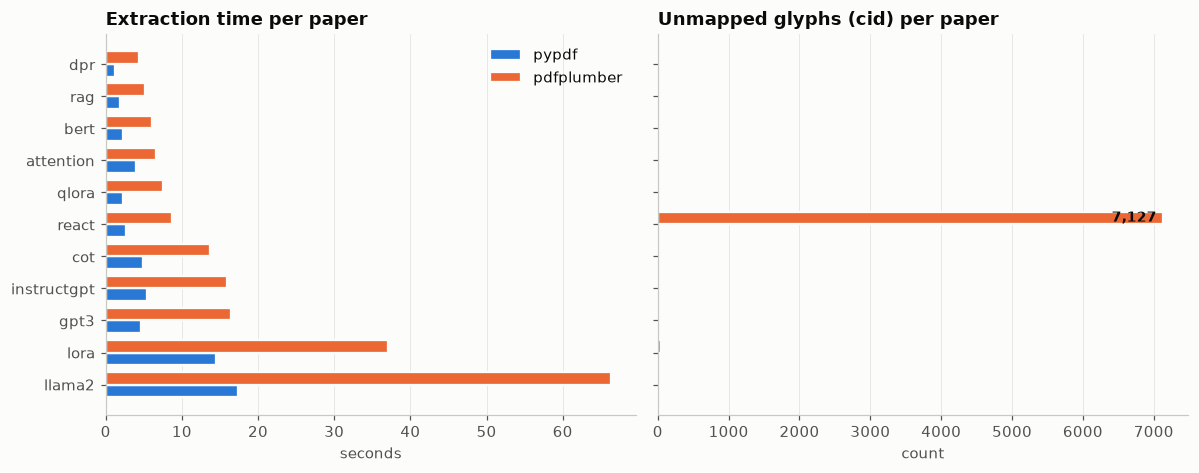

In [4]:
def grouped_barh(ax, table, columns, title, xlabel):
    # Horizontal grouped bars, one colour per column in fixed order, a surface-coloured gap between bars.
    rows = range(len(table))
    height = 0.8 / len(columns)
    for k, col in enumerate(columns):
        ax.barh([r + (k - (len(columns) - 1) / 2) * height for r in rows], table[col], height=height,
                color=SERIES[k], edgecolor=SURFACE, linewidth=1.5, label=col)
    ax.set_yticks(list(rows), table.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)

wide = loader_cmp.pivot(index="paper_id", columns="loader")
order = wide[("seconds", "pdfplumber")].sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
grouped_barh(ax1, wide["seconds"].loc[order], ["pypdf", "pdfplumber"], "Extraction time per paper", "seconds")
grouped_barh(ax2, wide["cid_glyphs"].loc[order], ["pypdf", "pdfplumber"], "Unmapped glyphs (cid) per paper", "count")
react_cid = wide.loc["react", ("cid_glyphs", "pdfplumber")]
ax2.annotate(f"{react_cid:,}", xy=(react_cid, list(order).index("react") + 0.2), xytext=(-4, 0),
             textcoords="offset points", ha="right", va="center", color=INK, fontsize=9, fontweight="bold")
ax1.legend(loc="upper right")
fig.tight_layout()

A sample makes the difference concrete: the ReAct page where `pdfplumber` produced the most unmapped glyphs, read by both loaders.

In [5]:
from rpab.loaders import discover_pdfs, identify, load_catalog, load_pdf, page_stats

catalog = load_catalog(CONFIG.paths.catalog)
react_pdf = next(p for p in discover_pdfs(CONFIG.paths.pdf_dir) if "2210.03629" in p.name)
react_meta = identify(react_pdf, catalog)
plumber_pages = load_pdf(react_pdf, react_meta, "pdfplumber")
worst = page_stats(plumber_pages, CONFIG.empty_page_chars).sort_values("cid_glyphs").iloc[-1]
page_no = int(worst["page"])
pypdf_page = load_pdf(react_pdf, react_meta, "pypdf")[page_no - 1]

print(f"ReAct page {page_no}: {int(worst['cid_glyphs'])} unmapped glyphs with pdfplumber\n")
print("pdfplumber:\n" + plumber_pages[page_no - 1].page_content[:320] + "\n")
print("pypdf:\n" + pypdf_page.page_content[:320])

ReAct page 2: 3112 unmapped glyphs with pdfplumber

pdfplumber:
PublishedasaconferencepaperatICLR2023
(cid:11)(cid:20)(cid:12)(cid:3)(cid:43)(cid:82)(cid:87)(cid:86)(cid:83)(cid:82)(cid:87)(cid:3)(cid:52)(cid:36) (cid:11)(cid:20)(cid:71)(cid:12)(cid:3)(cid:53)(cid:72)(cid:36)(cid:70)(cid:87)(cid:3)(cid:11)(cid:53)(cid:72)(cid:68)(cid:86)(cid:82)(cid:81)(cid:3)(cid:14)(cid:3)(cid:36

pypdf:
Published as a conference paper at ICLR 2023
$FW7KLQN>)LUVW,QHHGWRILQGDSHSSHUVKDNHUPRUH
OLNHO\WRDSSHDULQFDELQHWVFRXQWHUWRSV@
$FW*RWRFDELQHW
2EV2QWKHFDELQHW\RXVHHDYDVH
+HUHWKHDJHQWJRWRFDELQHWWKHQFDELQHWWKHQFRXQWHUWRSDQG
$FW*RW


**Observations.**

- `pypdf` is about 3× faster: 61 s against 188 s for all 411 pages. Llama 2 alone takes 66 s with `pdfplumber`.
- `pdfplumber` leaves 7,286 unmapped `(cid:NN)` glyphs, 7,127 of them in ReAct, where figure text uses an embedded font with a custom encoding. That text is lost for good.
- `pypdf` extracts the same ReAct text as letters shifted by 29 code points (sample above). It looks like noise, but it is recoverable in cleaning. None of the metrics above counted it, which is why the sample check matters.
- `pypdf` leaves 1,760 ligatures and 969 line-break hyphens; both are mechanical to fix.
- Two-column papers (BERT, DPR) come out in the right column order; checked on DPR page 2.

**Decision.** Use `PyPDFLoader` (`CONFIG.pdf_loader = "pypdf"`): faster, more text, and its defects can all be repaired, while `pdfplumber`'s cannot.

### 2.3 Cleaning

Rules in `rpab/cleaning.py`, applied in order to every page:

1. Replace ligatures with plain letters ("ﬁ" → "fi").
2. Decode shifted-font lines. Some ReAct figures embed a font whose character codes sit 29 below the real letters, so pypdf extracts "Think" as "7KLQN" and the space as the control character U+0003. A line where U+0003 outnumbers real spaces is shifted back; any other stray control character (a symbol glyph such as a check mark) is deleted.
3. Remove the arXiv side stamp (e.g. `arXiv:1706.03762v7 [cs.CL] 2 Aug 2023`).
4. Drop repeated header/footer lines: a line at a page's top or bottom edge whose shape (digits → `#`) appears at the edges of at least half the paper's pages. This removes page numbers and running heads.
5. Re-join words hyphenated across a line break ("ef-⏎ficient" → "efficient").
6. Normalise whitespace.

The raw text stays next to the cleaned text in `artifacts/pages.parquet`, so any cleaning decision can be audited later.

In [6]:
from rpab.cleaning import clean_documents

pages, page_log = clean_documents(raw_pages, CONFIG.repeated_line_share)
page_table = page_log.merge(page_stats(pages, CONFIG.empty_page_chars), on=["paper_id", "page"])
CONFIG.paths.artifacts_dir.mkdir(parents=True, exist_ok=True)
page_table.to_parquet(CONFIG.paths.pages, index=False)

rule_cols = ["ligatures_fixed", "shifted_lines_decoded", "control_chars_removed", "arxiv_stamps_removed",
             "edge_lines_removed", "hyphens_joined"]
cleaning = page_log.groupby("paper_id")[rule_cols].sum()
cleaning.loc["total"] = cleaning.sum()
cleaning

,ligatures_fixed,shifted_lines_decoded,control_chars_removed,arxiv_stamps_removed,edge_lines_removed,hyphens_joined
paper_id,,,,,,
attention,0,0,0,1,14,16
bert,157,0,0,1,0,332
cot,288,0,17,1,47,48
dpr,92,0,9,1,0,232
gpt3,444,0,0,1,74,23
instructgpt,352,0,0,1,77,43
llama2,0,0,1,1,76,66
lora,210,0,0,1,26,85
qlora,0,0,8,1,25,47


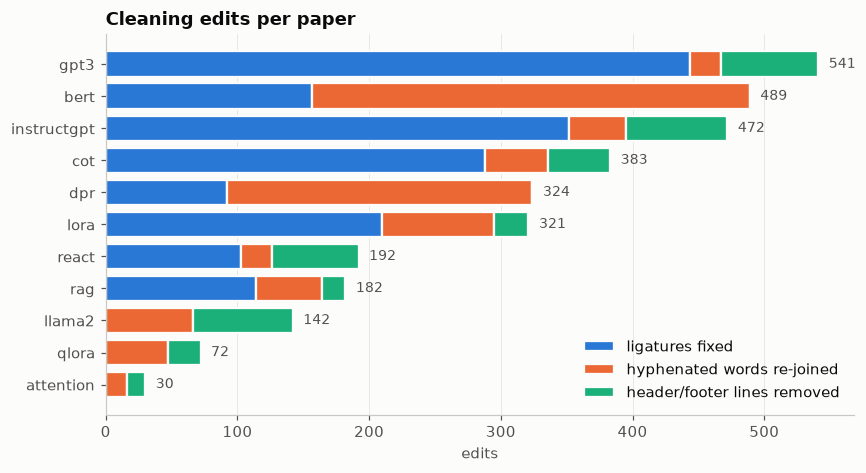

In [7]:
impact = page_log.groupby("paper_id")[["ligatures_fixed", "hyphens_joined", "edge_lines_removed"]].sum()
impact = impact.loc[impact.sum(axis=1).sort_values().index]
labels = {"ligatures_fixed": "ligatures fixed", "hyphens_joined": "hyphenated words re-joined",
          "edge_lines_removed": "header/footer lines removed"}

fig, ax = plt.subplots(figsize=(8, 4.4))
left = pd.Series(0, index=impact.index)
for k, col in enumerate(labels):
    ax.barh(impact.index, impact[col], left=left, color=SERIES[k], edgecolor=SURFACE, linewidth=1.5, label=labels[col])
    left = left + impact[col]
for y, total in enumerate(left):
    ax.text(total + 8, y, f"{int(total)}", va="center", color=INK_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_title("Cleaning edits per paper")
ax.set_xlabel("edits")
ax.legend(loc="lower right")
fig.tight_layout()

In [8]:
example = page_log[(page_log["paper_id"] == "dpr") & (page_log["page"] == 1)].iloc[0]
print("RAW:\n" + example["raw_text"][:430] + "\n")
print("CLEAN:\n" + example["clean_text"][:430])

RAW:
Dense Passage Retrieval for Open-Domain Question Answering
Vladimir Karpukhin∗, Barlas O˘guz∗, Sewon Min†, Patrick Lewis,
Ledell Wu, Sergey Edunov, Danqi Chen‡, Wen-tau Yih
Facebook AI †University of Washington ‡Princeton University
{vladk, barlaso, plewis, ledell, edunov, scottyih }@fb.com
sewon@cs.washington.edu
danqic@cs.princeton.edu
Abstract
Open-domain question answering relies on ef-
ﬁcient passage retrieval to select c

CLEAN:
Dense Passage Retrieval for Open-Domain Question Answering
Vladimir Karpukhin∗, Barlas O˘guz∗, Sewon Min†, Patrick Lewis,
Ledell Wu, Sergey Edunov, Danqi Chen‡, Wen-tau Yih
Facebook AI †University of Washington ‡Princeton University
{vladk, barlaso, plewis, ledell, edunov, scottyih }@fb.com
sewon@cs.washington.edu
danqic@cs.princeton.edu
Abstract
Open-domain question answering relies on efficient passage retrieval to select ca


**Observations.**

- 1,760 ligatures fixed and 965 hyphenated words re-joined. BERT and DPR, both two-column with narrow lines, account for most re-joins.
- 423 header/footer lines removed: page numbers in nine papers plus ReAct's running head. BERT and DPR have no repeated edge lines, so nothing was removed there.
- 198 ReAct figure lines decoded from the shifted font; the agent trajectories in its Figure 1 now read "Act 1: Think[First I need to find a pepper shaker…". 64 stray symbol characters removed in five papers.
- The first version of rule 2 shifted any line containing a control character and corrupted 30 normal lines in CoT, DPR, QLoRA and Llama 2, where a single check-mark glyph triggered it. Requiring U+0003 to outnumber real spaces fixed that; the affected lines were checked one by one.
- Known limits: a shifted line holding one word has no space to detect, so two ReAct figure labels stay garbled ("VRIWZDUH" is "software"). Footnote marks (∗ † ‡) and split accents ("O˘guz") remain. Neither matters for retrieval.

**Decision.** Keep all six rules. The raw text stays in `artifacts/pages.parquet` beside the cleaned text.

### 2.4 Quality report

In [9]:
from rpab.loaders import quality_report

stats = page_stats(pages, CONFIG.empty_page_chars)
print(f"Empty pages (OCR candidates): {int(stats['is_empty'].sum())} of {len(stats)}")
quality_report(stats)

Empty pages (OCR candidates): 0 of 411


,pages,empty_pages,total_chars,mean_chars_per_page,min_chars_per_page,ligatures,cid_glyphs,hyphen_breaks,non_ascii_share
paper_id,,,,,,,,,
llama2,77,0,260023,3376.922,156,0,0,0,0.003
gpt3,75,0,236810,3157.467,100,0,0,0,0.004
instructgpt,68,0,181751,2672.809,348,0,0,0,0.003
cot,43,0,135506,3151.302,634,0,0,0,0.003
react,33,0,108365,3283.788,597,0,0,0,0.002
qlora,26,0,87637,3370.654,383,0,0,0,0.002
lora,26,0,82360,3167.692,1771,0,0,0,0.006
rag,19,0,68962,3629.579,1129,0,0,0,0.003
bert,16,0,63502,3968.875,2324,0,0,0,0.002


**Observations.** 0 of 411 pages are empty, and no ligatures, unmapped glyphs or line-break hyphens remain after cleaning, so every PDF has a usable text layer. The shortest pages (100 to 400 characters) are figure or table pages, not extraction failures.

**Decision.** OCR is not needed for this corpus. The empty-page count stays in the ingestion report, so a scanned PDF added later would be flagged.

### 2.5 Exploring the corpus

Corpus: 357,295 tokens


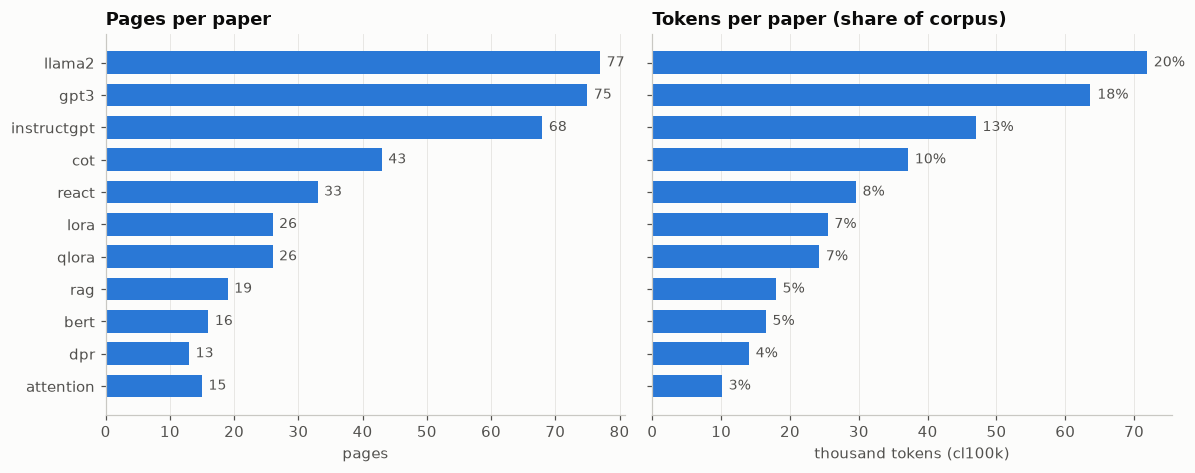

In [10]:
from rpab.eda import back_matter_split, count_tokens

page_table["tokens"] = count_tokens(page_table["clean_text"])
per_paper = page_table.groupby("paper_id").agg(pages=("page", "count"), tokens=("tokens", "sum"))
per_paper["token_share"] = per_paper["tokens"] / per_paper["tokens"].sum()
per_paper = per_paper.sort_values("tokens")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
ax1.barh(per_paper.index, per_paper["pages"], color=SERIES[0], height=0.7)
for y, v in enumerate(per_paper["pages"]):
    ax1.text(v + 1, y, str(v), va="center", color=INK_2, fontsize=9)
ax1.set_title("Pages per paper")
ax1.set_xlabel("pages")
ax2.barh(per_paper.index, per_paper["tokens"] / 1000, color=SERIES[0], height=0.7)
for y, (v, s) in enumerate(zip(per_paper["tokens"], per_paper["token_share"])):
    ax2.text(v / 1000 + 1, y, f"{s:.0%}", va="center", color=INK_2, fontsize=9)
ax2.set_title("Tokens per paper (share of corpus)")
ax2.set_xlabel("thousand tokens (cl100k)")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
print(f"Corpus: {per_paper['tokens'].sum():,} tokens")

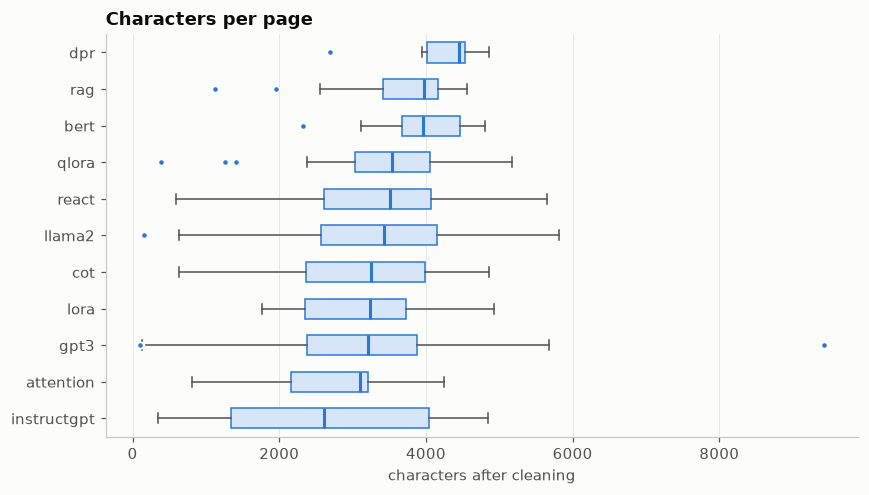

In [11]:
order = page_table.groupby("paper_id")["n_chars"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.boxplot([page_table.loc[page_table["paper_id"] == p, "n_chars"] for p in order], orientation="horizontal",
           tick_labels=list(order), widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#d6e6f8", edgecolor=SERIES[0]), medianprops=dict(color=SERIES[0], linewidth=2),
           whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2),
           flierprops=dict(marker="o", markersize=4, markerfacecolor=SERIES[0], markeredgecolor=SURFACE))
ax.grid(axis="y", visible=False)
ax.set_title("Characters per page")
ax.set_xlabel("characters after cleaning")
fig.tight_layout()

,references_page,body_pages,back_matter_pages,total_pages
paper_id,,,,
dpr,9,8,5,13
attention,10,9,6,15
bert,10,9,7,16
rag,10,9,10,19
qlora,17,16,10,26
lora,13,12,14,26
react,10,9,24,33
cot,10,9,34,43
instructgpt,21,20,48,68


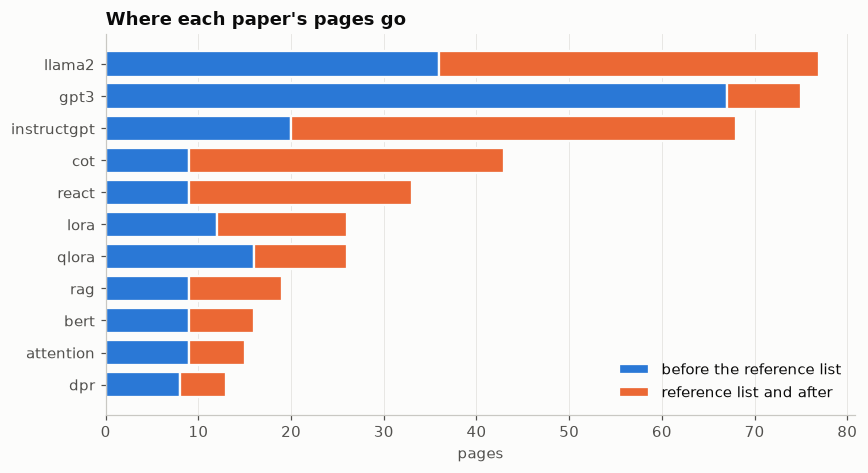

In [12]:
split = back_matter_split(page_table).sort_values("total_pages")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(split.index, split["body_pages"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="before the reference list")
ax.barh(split.index, split["back_matter_pages"], left=split["body_pages"], color=SERIES[1], edgecolor=SURFACE,
        linewidth=1.5, label="reference list and after")
ax.grid(axis="y", visible=False)
ax.set_title("Where each paper's pages go")
ax.set_xlabel("pages")
ax.legend(loc="lower right")
fig.tight_layout()
split

**Observations.**

- The corpus is 411 pages and about 361k tokens. Three long papers hold just over half of it: Llama 2 (20%), GPT-3 (18%) and InstructGPT (13%). Attention Is All You Need is only 3%.
- Pages hold a median of 3,404 characters (middle half: 2,409 to 4,079). An 800-character chunk is about a quarter of a page, so most pages yield 4 to 5 chunks.
- In six papers more than half the pages come after the reference list starts: CoT 34 of 43, InstructGPT 48 of 68, ReAct 24 of 33, Llama 2 41 of 77, LoRA 14 of 26, RAG 10 of 19. GPT-3 is the exception because its appendices come before its references.

**Implications for the next steps.**

- Long papers will contribute the most chunks and so get more chances to appear in the top results. The evaluation questions must cover the short papers too, and retrieval results will be checked per paper.
- Appendices hold real content (extra experiments, prompts, model details) and stay in the index. Reference lists are mostly author names and venues; whether removing them improves retrieval will be tested as a chunking variant in section 3.
- Chunks must not cross page boundaries, so chunk size has to sit well below the typical page length. The 500, 800 and 1,200-character variants all do.

## 3. Chunking experiments

**Intent.** Pick the chunking that puts the passage holding the answer in the top 3. Every variant splits one page at a time, so a chunk never crosses a page boundary and its page number is exact; chunks under 100 characters (stray figure labels) are dropped. Each chunk gets a deterministic id, `{paper_id}_p{page:03d}_c{index:03d}`, and a SHA-256 of its text that keys the embedding cache.

**Method.** Each grid point is embedded with one model (`bge-m3`), stored in its own Chroma collection and scored with dense top-10 retrieval on the **dev** questions only. A retrieved chunk is a hit when it comes from a gold paper *and* a gold page. Held-out questions are not touched until final reporting.

### 3.1 Evaluation set (draft)

25 questions in `data/eval/eval_questions.json`: 20 answerable, spread over all 11 papers and five question types, and 5 out of scope (two of them deliberately close to the corpus: GPT-4 and Mamba). 10 questions (40%) are `held_out`. Gold pages were found by searching the cleaned page text and reading each passage; the reference answers are drafts for the author to review.

split     answerable
dev       False          3
          True          12
held_out  False          2
          True           8 

split          dev  held_out
type                        
comparison       1         1
conceptual       4         1
factual          0         2
method_detail    4         1
numeric          3         3


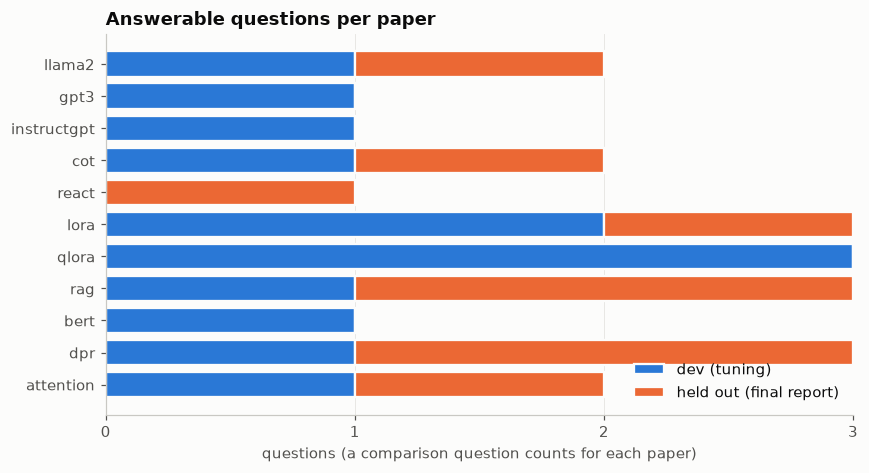

In [13]:
import json

eval_set = json.loads(CONFIG.paths.eval_questions.read_text(encoding="utf-8"))
eval_df = pd.DataFrame(eval_set)
print(eval_df.groupby(["split", "answerable"]).size().rename("questions").to_string(), "\n")
print(eval_df[eval_df["answerable"]].groupby(["type", "split"]).size().unstack(fill_value=0).to_string())

coverage = (eval_df[eval_df["answerable"]].explode("gold_papers")
            .groupby(["gold_papers", "split"]).size().unstack(fill_value=0)
            .reindex(per_paper.index, fill_value=0))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(coverage.index, coverage["dev"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="dev (tuning)")
ax.barh(coverage.index, coverage["held_out"], left=coverage["dev"], color=SERIES[1], edgecolor=SURFACE,
        linewidth=1.5, label="held out (final report)")
ax.grid(axis="y", visible=False)
ax.set_title("Answerable questions per paper")
ax.set_xlabel("questions (a comparison question counts for each paper)")
ax.set_xticks(range(0, int(coverage.sum(axis=1).max()) + 1))
ax.legend(loc="lower right")
fig.tight_layout()

### 3.2 Chunking grid

The grid from the technical plan, plus two capped semantic variants: the semantic chunker has no size limit, so those re-split any chunk longer than 1,200 characters. Sizes are characters for `recursive` and tokens (cl100k) for `fixed`.

In [14]:
from rpab.chunking import ChunkSpec
from rpab.embeddings import load_embedder
from rpab.evaluation import load_eval_set, read_experiments
from rpab.experiments import CHUNK_GRID, run_chunking_grid
from rpab.vectorstore import get_client

dev = load_eval_set(CONFIG.paths.eval_questions, split="dev")
client = get_client(CONFIG.paths.chroma_dir)
bge = load_embedder("open", CONFIG)
NOREF = [ChunkSpec("recursive", 1200, 150, drop_references=True), ChunkSpec("fixed", 512, 0, drop_references=True)]
chunk_results_path = CONFIG.paths.artifacts_dir / "chunking_per_question.parquet"

if RUN_EXPERIMENTS or not chunk_results_path.exists():
    chunk_results = run_chunking_grid(CHUNK_GRID + NOREF, page_table, bge, client, dev, CONFIG)
    chunk_results.to_parquet(chunk_results_path, index=False)
else:
    chunk_results = pd.read_parquet(chunk_results_path)

grid = read_experiments(CONFIG.paths.experiments, "chunking").set_index("chunking")
grid_cols = ["run_id", "hit_at_1", "hit_at_3", "hit_at_5", "mrr", "precision_at_3", "num_chunks",
             "mean_chunk_chars", "embed_seconds", "index_size_mb", "notes"]
grid.loc[~grid.index.str.endswith("_noref"), grid_cols].sort_values(["hit_at_3", "mrr"], ascending=False)

C:\Users\Asus\Desktop\Research Paper Answer Bot\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1023 23:07:00.916000 25392 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-m3'.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   1%|▏         | 5/391 [00:00<00:54,  7.13it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 544.68it/s]

,run_id,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,num_chunks,mean_chunk_chars,embed_seconds,index_size_mb,notes
chunking,,,,,,,,,,,
semantic_p95,exp_012,0.667,0.917,0.917,0.806,0.444,1131,1159.3,20.2,4.6,chunking took 88.8 s
semantic_p90,exp_011,0.583,0.917,0.917,0.764,0.444,1576,827.8,15.4,6.5,chunking took 89.0 s
fixed_512_0,exp_009,0.583,0.917,0.917,0.736,0.361,891,1479.8,15.8,3.6,chunking took 0.8 s
recursive_1200_150,exp_005,0.667,0.833,0.917,0.747,0.444,1418,1005.5,17.8,5.8,chunking took 0.4 s
recursive_800_200,exp_004,0.583,0.833,0.833,0.733,0.500,2277,705.9,18.4,9.3,chunking took 0.4 s
semantic_p90_max1200_150,exp_013,0.500,0.833,0.833,0.637,0.444,2022,666.0,19.6,8.3,chunking took 90.5 s
fixed_512_50,exp_010,0.750,0.750,1.000,0.812,0.361,943,1505.0,13.7,3.9,chunking took 0.7 s
recursive_500_100,exp_001,0.750,0.750,0.750,0.778,0.444,3376,439.0,18.9,13.8,chunking took 0.7 s
semantic_p95_max1200_150,exp_014,0.667,0.750,0.833,0.739,0.389,1740,785.8,16.9,7.1,chunking took 89.2 s


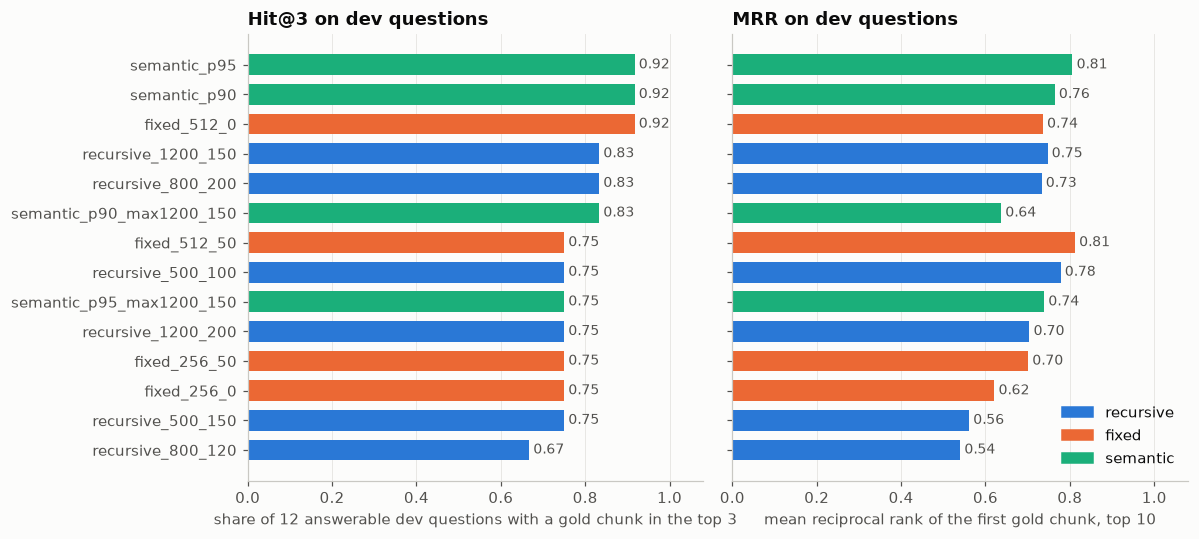

In [15]:
main_grid = grid[~grid.index.str.endswith("_noref")].sort_values(["hit_at_3", "mrr"])
colours = main_grid["chunking_strategy"].map({"recursive": SERIES[0], "fixed": SERIES[1], "semantic": SERIES[2]})
n_dev = sum(q["answerable"] for q in dev)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, col, title in [(ax1, "hit_at_3", "Hit@3 on dev questions"), (ax2, "mrr", "MRR on dev questions")]:
    ax.barh(main_grid.index, main_grid[col], color=colours, height=0.7)
    for y, v in enumerate(main_grid[col]):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK_2, fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
ax1.set_xlabel(f"share of {n_dev} answerable dev questions with a gold chunk in the top 3")
ax2.set_xlabel("mean reciprocal rank of the first gold chunk, top 10")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SERIES]
ax2.legend(handles, ["recursive", "fixed", "semantic"], loc="lower right")
fig.tight_layout()

With 12 answerable dev questions, one question moves hit@3 by 0.083. The rank of the first gold chunk per question shows where the configurations really differ (`<NA>` = not in the top 10):

In [16]:
ranks = chunk_results.assign(rank=(1 / chunk_results["reciprocal_rank"]).where(chunk_results["reciprocal_rank"] > 0))
ranks.pivot(index="question_id", columns="chunking", values="rank")[main_grid.index[::-1]].T.astype("Int64")

question_id,q001,q003,q004,q006,q008,q009,q011,q013,q015,q016,q018,q019
chunking,,,,,,,,,,,,
semantic_p95,1,1,2,1,1,2,2,1,1,1,1,6
semantic_p90,1,1,2,1,1,2,2,2,1,1,1,6
fixed_512_0,1,3,3,1,1,1,1,1,2,2,1,6
recursive_1200_150,1,5,3,1,1,1,3,1,1,1,1,10
recursive_800_200,1,1,6,1,2,2,1,2,1,1,1,8
semantic_p90_max1200_150,1,3,3,1,1,7,3,2,1,1,1,<NA>
fixed_512_50,1,4,4,1,1,1,1,1,4,1,1,1
recursive_500_100,1,1,6,1,1,<NA>,1,1,1,1,1,6
semantic_p95_max1200_150,1,1,4,1,1,7,1,3,1,1,1,7


recursive_1200_150: 0 chunks over 1,024 tokens, longest 912
fixed_512_0: 0 chunks over 1,024 tokens, longest 513
semantic_p95: 14 chunks over 1,024 tokens, longest 6973


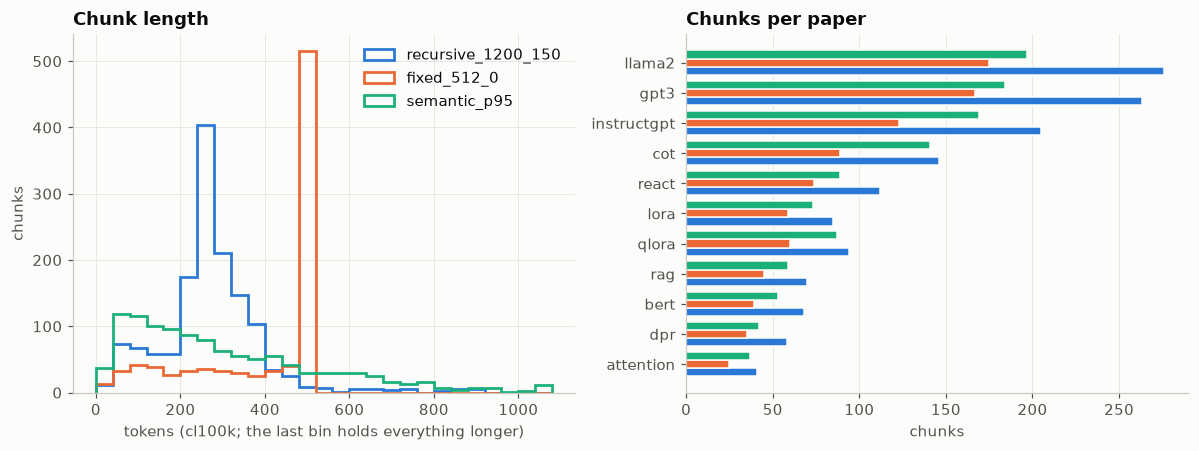

In [17]:
grid_chunks = {slug: pd.read_parquet(CONFIG.paths.chunk_grid_dir / f"{slug}.parquet")
               for slug in ["recursive_1200_150", "fixed_512_0", "semantic_p95"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
bins = range(0, 1100, 40)
for k, (slug, chunks) in enumerate(grid_chunks.items()):
    ax1.hist(chunks["token_count"].clip(upper=1080), bins=bins, histtype="step", linewidth=1.8, color=SERIES[k], label=slug)
ax1.set_title("Chunk length")
ax1.set_xlabel("tokens (cl100k; the last bin holds everything longer)")
ax1.set_ylabel("chunks")
ax1.legend(loc="upper right")

counts = pd.DataFrame({slug: c.groupby("paper_id").size() for slug, c in grid_chunks.items()}).loc[per_paper.index]
rows = range(len(counts))
for k, slug in enumerate(counts.columns):
    ax2.barh([r + (k - 1) * 0.27 for r in rows], counts[slug], height=0.27, color=SERIES[k], edgecolor=SURFACE, linewidth=1)
ax2.set_yticks(list(rows), counts.index)
ax2.grid(axis="y", visible=False)
ax2.set_title("Chunks per paper")
ax2.set_xlabel("chunks")
fig.tight_layout()
for slug, c in grid_chunks.items():
    print(f"{slug}: {(c['token_count'] > 1024).sum()} chunks over 1,024 tokens, longest {c['token_count'].max()}")

### 3.3 Dropping reference lists

Section 2 found that reference lists fill many pages. A chunk is treated as bibliography when it has at least 4 years *and* at least 1 venue word (Proceedings, arXiv, Conference, URL...) per 1,000 characters; heavily cited body text has years but almost never venue words. The two best bounded configurations are re-run without those chunks.

In [18]:
from rpab.chunking import looks_like_references

noref = grid.loc[[s.slug for s in NOREF] + [s.slug.removesuffix("_noref") for s in NOREF], grid_cols[:8]]
display(noref)
full = grid_chunks["fixed_512_0"]
flagged = full[full["text"].map(looks_like_references)]
print(f"fixed_512_0: {len(flagged)} of {len(full)} chunks dropped as bibliography; per paper:",
      flagged.groupby("paper_id").size().to_dict())
print("\nSample dropped chunk:\n" + flagged.sample(1, random_state=CONFIG.seed)["text"].iloc[0][:300])

,run_id,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,num_chunks,mean_chunk_chars
chunking,,,,,,,,
recursive_1200_150_noref,exp_015,0.667,0.833,0.917,0.747,0.444,1242,1005.8
fixed_512_0_noref,exp_016,0.583,0.917,0.917,0.736,0.333,766,1501.7
recursive_1200_150,exp_005,0.667,0.833,0.917,0.747,0.444,1418,1005.5
fixed_512_0,exp_009,0.583,0.917,0.917,0.736,0.361,891,1479.8


fixed_512_0: 125 of 891 chunks dropped as bibliography; per paper: {'attention': 4, 'bert': 7, 'cot': 12, 'dpr': 5, 'gpt3': 22, 'instructgpt': 14, 'llama2': 19, 'lora': 11, 'qlora': 13, 'rag': 13, 'react': 5}

Sample dropped chunk:
QA: A
question answering challenge targeting commonsense knowledge. NAACL.
Alon Talmor, Oyvind Tafjord, Peter Clark, Yoav Goldberg, and Jonathan Berant. 2020. Leap-ofthought: Teaching pre-trained models to systematically reason over implicit knowledge. NeurIPS.
Alon Talmor, Ori Yoran, Ronan Le Bras,


**Observations.**

- Hit@3 ranges from 0.667 to 0.917. Three configurations tie at the top with 11 of 12 questions: `semantic_p95`, `semantic_p90` and `fixed_512_0`. Six more are one question behind.
- Larger chunks do somewhat better, mostly lower in the ranking: the five configurations averaging 1,000+ characters average hit@3 0.833, hit@5 0.934 and MRR 0.761, against 0.778, 0.805 and 0.675 for the nine smaller ones. The hit@3 gap is under one question, and `semantic_p90` (828 characters) is among the best. Part of this is the metric itself: gold labels are pages, so a chunk covering more of a page is more likely to count as a hit. Larger chunks also carry more topic signal per vector.
- Overlap has no consistent effect: 800 characters gains from 120 → 200, 1,200 characters loses from 150 → 200, and 512 tokens loses one hit@3 question with 50 tokens of overlap but gains MRR (0.812) and hit@5 (1.000). At this sample size these are single-question swings.
- q019 (LoRA vs QLoRA) is the hardest question: its first gold chunk sits at rank 6 to 10, or outside the top 10, in every configuration except `fixed_512_50`. A single dense query has to match two papers at once. That is a case for hybrid search and multi-query in section 6. q004 (in-batch negatives) is the other weak spot, at rank 2 to 8.
- The semantic chunker matches the top score but leaves 14 chunks over 1,024 tokens (the longest, 6,973 tokens, is a table page with no breakpoint). bge-m3 truncates those at its 1,024-token cap. It also takes about 89 s per run because it embeds every sentence. Capping its chunks at 1,200 characters drops hit@3 to 0.750–0.833, so its advantage came from large chunks, not from where it breaks.
- Dropping bibliography chunks removes 125 of 891 chunks (14%) from `fixed_512_0` and 176 from `recursive_1200_150`, and changes no metric. The sample confirms the filter catches reference entries.
- Embedding each grid point with bge-m3 takes 12–21 s on the RTX 4060; vector storage ranges from 3.6 MB (fixed 512) to 15.7 MB (recursive 500).

**Decision.** Use **`fixed_512_0_noref`**: 512-token chunks, no overlap, bibliography chunks dropped (`CONFIG.chunking_strategy = "fixed"`, `chunk_size = 512`, `chunk_overlap = 0`, `drop_references = True`). It ties for the best hit@3, its chunks never exceed 513 tokens, so nothing is truncated and three passages (about 1,200 tokens) fit easily in the 8k context. It also gives the smallest index (766 chunks), and chunking is instant and needs no model. Known risk: a fixed token window can cut a sentence in two. `fixed_512_50` stays in the log as the alternative if the failure analysis in section 8 finds answers split across chunks. With 12 dev questions the top tier cannot be told apart reliably, so this choice is provisional until the held-out results.

## 4. Embedding model comparison

**Intent.** Compare one open-source and one commercial embedding model on the chosen chunking, with the same chunks and the same dev questions, and pick the one the bot uses.

| | `BAAI/bge-m3` | `gemini-embedding-001` |
|---|---|---|
| Type | open-source, runs locally on the GPU (float16) | commercial API, free tier |
| Dimensions | 1,024 | 3,072 |
| Query vs document | same encoder, no prefix | task types `RETRIEVAL_QUERY` / `RETRIEVAL_DOCUMENT` |

Gemini requests carry 50 texts, are paced to stay under the per-minute token limit and retry with backoff on rate-limit errors. Every document vector is cached by text hash, so nothing is embedded twice. The local model is timed by re-embedding from scratch; Gemini's time is its first (uncached) run.

In [19]:
from rpab.experiments import run_embedding_comparison

chunks = pd.read_parquet(CONFIG.paths.chunk_grid_dir / f"{CONFIG.chunk_spec.slug}.parquet")
emb_results_path = CONFIG.paths.artifacts_dir / "embedding_per_question.parquet"
gemini = load_embedder("commercial", CONFIG)
embedders = {"bge-m3": bge, "gemini": gemini}

if RUN_EXPERIMENTS or not emb_results_path.exists():
    emb_results = run_embedding_comparison(CONFIG.chunk_spec, chunks, list(embedders.values()), client, dev, CONFIG)
    emb_results.to_parquet(emb_results_path, index=False)
else:
    emb_results = pd.read_parquet(emb_results_path)

emb_table = read_experiments(CONFIG.paths.experiments, "embedding").set_index("embedding_model")
emb_table["dim"] = [bge.dim if "bge" in m else gemini.dim for m in emb_table.index]
emb_table[["run_id", "chunking", "hit_at_1", "hit_at_3", "hit_at_5", "mrr", "precision_at_3", "latency_ms",
           "embed_seconds", "dim", "index_size_mb", "cost_usd"]]

,run_id,chunking,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,latency_ms,embed_seconds,dim,index_size_mb,cost_usd
embedding_model,,,,,,,,,,,,
BAAI/bge-m3,exp_017,fixed_512_0_noref,0.583,0.917,0.917,0.736,0.361,27.4,10.9,1024,3.1,0.0000
models/gemini-embedding-001,exp_018,fixed_512_0_noref,0.750,1.000,1.000,0.833,0.444,474.0,882.1,3072,9.4,0.0457


In [20]:
emb_ranks = emb_results.assign(rank=(1 / emb_results["reciprocal_rank"]).where(emb_results["reciprocal_rank"] > 0))
emb_ranks.pivot(index="question_id", columns="embedding_model", values="rank").astype("Int64")

embedding_model,BAAI/bge-m3,models/gemini-embedding-001
question_id,,
q001,1,1
q003,3,1
q004,3,3
q006,1,1
q008,1,1
q009,1,1
q011,1,3
q013,1,1
q015,2,3


### 4.1 Manual sanity queries

Five questions that are **not** in the eval set, answered by both collections. The top 3 chunks are read by hand to judge whether they are on topic, and whether `paper_title` and `page` came through intact.

In [21]:
from rpab.vectorstore import collection_name, dense_search

SANITY = [
    "What optimizer and learning rate schedule were used to train the Transformer?",
    "Which corpora was BERT pre-trained on?",
    "Which weight matrices of the Transformer does LoRA adapt in its experiments?",
    "What is a paged optimizer?",
    "How does ReAct compare with chain-of-thought prompting on HotpotQA?",
]
rows = []
for name, embedder in embedders.items():
    collection = client.get_collection(collection_name(embedder.slug, CONFIG.chunk_spec.slug))
    for q_num, question in enumerate(SANITY, start=1):
        for rank, hit in enumerate(dense_search(collection, embedder, question, 3), start=1):
            rows.append({"query": q_num, "model": name, "rank": rank, "paper_title": hit["paper_title"][:38],
                         "page": hit["page"], "score": hit["score"], "snippet": hit["text"][:110].replace("\n", " ")})
sanity = pd.DataFrame(rows).set_index(["query", "model", "rank"])
for q_num, question in enumerate(SANITY, start=1):
    print(f"Q{q_num}. {question}")
sanity

Q1. What optimizer and learning rate schedule were used to train the Transformer?
Q2. Which corpora was BERT pre-trained on?
Q3. Which weight matrices of the Transformer does LoRA adapt in its experiments?
Q4. What is a paged optimizer?
Q5. How does ReAct compare with chain-of-thought prompting on HotpotQA?


paper_title  page   score  \
query model  rank                                                         
1     bge-m3 1                  Attention Is All You Need     8  0.6124   
             2                  Attention Is All You Need     7  0.6087   
             3     LoRA: Low-Rank Adaptation of Large Lan     9  0.5853   
2     bge-m3 1     BERT: Pre-training of Deep Bidirection     3  0.5630   
             2     BERT: Pre-training of Deep Bidirection     1  0.5302   
             3     BERT: Pre-training of Deep Bidirection     5  0.5117   
3     bge-m3 1     LoRA: Low-Rank Adaptation of Large Lan     5  0.7000   
             2     LoRA: Low-Rank Adaptation of Large Lan     4  0.6318   
             3     LoRA: Low-Rank Adaptation of Large Lan     1  0.6314   
4     bge-m3 1     QLoRA: Efficient Finetuning of Quantiz     5  0.4901   
             2     LoRA: Low-Rank Adaptation of Large Lan     9  0.4786   
             3     Retrieval-Augmented Generation for Kno     4  0.4736   
5     bge-m3 1     ReAct: Synergizing Reasoning and Actin     3  0.7171   
             2     ReAct: Synergizing Reasoning and Actin     2  0.7098   
             3     ReAct: Synergizing Reasoning and Actin     5  0.7005   
1     gemini 1                  Attention Is All You Need     7  0.7826   
             2     Training language models to follow ins    40  0.7369   
             3     Training language models to follow ins    41  0.7335   
2     gemini 1     BERT: Pre-training of Deep Bidirection     5  0.7830   
             2     BERT: Pre-training of Deep Bidirection    14  0.7510   
             3     BERT: Pre-training of Deep Bidirection     3  0.7496   
3     gemini 1     LoRA: Low-Rank Adaptation of Large Lan     5  0.8012   
             2     LoRA: Low-Rank Adaptation of Large Lan    10  0.7892   
             3     LoRA: Low-Rank Adaptation of Large Lan     2  0.7873   
4     gemini 1     QLoRA: Efficient Finetuning of Quantiz     5  0.7197   
             2     QLoRA: Efficient Finetuning of Quantiz     3  0.6804   
             3     QLoRA: Efficient Finetuning of Quantiz     5  0.6689   
5     gemini 1     ReAct: Synergizing Reasoning and Actin     5  0.8163   
             2     ReAct: Synergizing Reasoning and Actin     5  0.8141   
             3     ReAct: Synergizing Reasoning and Actin    14  0.8103   

                                                                                                     snippet  
query model  rank                                                                                             
1     bge-m3 1     , establishing a new state-of-the-art BLEU score of 28.4. The configuration of this mo...  
             2     machine with 8 NVIDIA P100 GPUs. For our base models using the hyperparameters describ...  
             3     tasks. Note that the low-rank structure not only lowers the hardware barrier to entry ...  
2     bge-m3 1     BERT BERT E[CLS] E1 E[SEP]... EN E1’ ... EM’ C T1 T[SEP]... TN T1’ ... TM’ [CLS] Tok 1...  
             2     BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding Jacob...  
             3     [CLS] he likes play ##ing [SEP]my dog is cute [SEP]Input E[CLS] Ehe Elikes Eplay E##in...  
3     bge-m3 1     guarantees that we do not introduce any additional latency during inference compared t...  
             2     Batch Size 32 16 1 Sequence Length 512 256 128 |Θ| 0.5M 11M 11M Fine-Tune/LoRA 1449.4±...  
             3     LORA: L OW-R ANK ADAPTATION OF LARGE LANGUAGE MODELS Edward Hu∗ Yelong Shen∗ Phillip W...  
4     bge-m3 1     use this feature to allocate paged memory for the optimizer states which are then auto...  
             2     guage models trained on a large amount of text – where fine-tuning on task-specific da...  
             3     minimize the negative marginal log-likelihood of each target,∑j− logp(yj|xj) using sto...  
5     bge-m3 1     We conduct empirical evaluations ofReAct and state-of-the-art baselines 

**Observations.**

- Gemini puts a gold chunk in the top 3 for all 12 dev questions (bge-m3: 11), with MRR 0.833 vs 0.736, hit@1 0.750 vs 0.583 and precision@3 0.444 vs 0.361.
- Per question, Gemini fixes the hard comparison q019 (rank 6 → 1) and q003 (3 → 1). bge-m3 is ahead on q011 (1 vs 3) and q015 (2 vs 3).
- Sanity queries: both models put the page that answers the question in the top 3 for all five. Gemini ranks it first in all five; bge-m3 in two (Q3, Q4). bge-m3's misses pull in off-topic chunks (a LoRA page for the Transformer optimizer, a RAG page for paged optimizers). Gemini's off-paper hits for Q1 are InstructGPT hyperparameter pages, which are at least about optimizer settings. Titles and pages came through intact in every result.
- Cost and speed: bge-m3 embeds the 766 chunks in 11 s locally, for free. Gemini took 882 s, almost all of it waiting, because requests are paced to the free tier's per-minute token limit. About 288k tokens were sent: free on the free tier, about $0.05 at the paid list price. A Gemini query takes about 470 ms (a network round trip) against about 30 ms locally. Its 3,072-dim vectors take 3× the space (9.4 vs 3.1 MB).
- Gemini adds dependencies: an internet connection, an API key, a daily quota, and query text sent to Google.

**Decision.** Use **`gemini-embedding-001`** for retrieval (`CONFIG.embedding_choice = "commercial"`), and keep the bge-m3 collection as the **offline fallback** (`CONFIG.embedding_fallback = "open"`), to be used when the API is unreachable or out of quota (wired into the app in M4). Gemini is better on every retrieval metric and on the sanity queries, and the half-second query latency is small next to LLM generation. The margin is one dev question, so the held-out evaluation in section 6 has to confirm it. Both collections stay indexed so section 6 can compare retrieval strategies on either model.

## 5. Vector database build

**Intent.** Persist the chosen chunks and their vectors so the bot can start without re-embedding, and prove the index is complete and consistent.

- `artifacts/chunks.parquet` is the canonical chunk table; Chroma and (in section 6) BM25 are rebuilt from it.
- One collection per embedding model × chunking, named `papers__{embedding}__{chunking}`, cosine distance, with the model, dimension, chunking and creation time stored as collection metadata. A query is refused if its embedder differs from the one recorded on the collection.
- `scripts/ingest.py chunk index` rebuilds both from the saved pages.

In [22]:
from rpab.vectorstore import build_collection, time_cold_reload, validate_collection

chunks.to_parquet(CONFIG.paths.chunks, index=False)
collections = {name: build_collection(client, embedder, chunks, CONFIG.chunk_spec.slug)
               for name, embedder in embedders.items()}
for collection in collections.values():
    validate_collection(collection, chunks)  # count = rows, citation fields present, ids unique
    print(f"checks passed: {collection.name} ({collection.count()} vectors)")

pd.DataFrame([{"collection": c.name, **c.metadata} for c in collections.values()]).set_index("collection").T

checks passed: papers__bge_m3__fixed_512_0_noref (766 vectors)
checks passed: papers__gemini_embedding_001__fixed_512_0_noref (766 vectors)


collection,papers__bge_m3__fixed_512_0_noref,papers__gemini_embedding_001__fixed_512_0_noref
hnsw:space,cosine,cosine
num_chunks,766,766
created_at,2026-10-23T17:16:21+00:00,2026-10-23T17:31:05+00:00
embedding_model,BAAI/bge-m3,models/gemini-embedding-001
chunk_size,512,512
chunking_strategy,fixed,fixed
chunking,fixed_512_0_noref,fixed_512_0_noref
chunk_overlap,0,0
embedding_dim,1024,3072


In [23]:
all_collections = sorted(c.name for c in client.list_collections())
print(f"{len(all_collections)} collections on disk, kept for comparison until the final choice is documented")

# Each row is a fresh Python process: open the index, load the query embedder, answer one query
kinds = {"bge-m3": "open", "gemini": "commercial"}
pd.DataFrame([time_cold_reload(c.name, kinds[name], SANITY[0]) for name, c in collections.items()]).set_index("collection")

17 collections on disk, kept for comparison until the final choice is documented


,vectors,open_index_s,load_embedder_s,first_query_s,total_s
collection,,,,,
papers__bge_m3__fixed_512_0_noref,766,2.2,11.8,0.4,14.4
papers__gemini_embedding_001__fixed_512_0_noref,766,2.8,1.3,0.6,4.7


In [24]:
# The paper filter behind the UI: a Chroma `where` clause on chunk metadata
filtered = dense_search(collections["bge-m3"], bge, "How much memory does finetuning save?", 3,
                        where={"paper_id": {"$in": ["lora", "qlora"]}})
pd.DataFrame(filtered)[["chunk_id", "paper_title", "page", "score"]]

,chunk_id,paper_title,page,score
0,qlora_p004_c000,QLoRA: Efficient Finetuning of Quantized LLMs,4,0.6028
1,qlora_p001_c001,QLoRA: Efficient Finetuning of Quantized LLMs,1,0.5992
2,lora_p001_c001,LoRA: Low-Rank Adaptation of Large Language Models,1,0.5938


**Observations.**

- Both collections pass the integrity checks: 766 vectors equal the 766 rows of `chunks.parquet`, every record has `paper_title` and `page`, and every `chunk_id` is unique. Each collection's metadata records its model, dimension, chunking and creation time.
- Cold start from a new process: the index itself opens in about 2–3 s. With Gemini the first answer is ready in about 6 s. With bge-m3 it takes 14 s when the weights are already in the operating system's file cache, and 29 s from a cold disk (seen on the first run); nearly all of it is loading PyTorch and 2.3 GB of weights. Both are under the 30 s target, the cold case only just, so the apps will load the model once at startup.
- The Chroma `where` filter limits a search to chosen papers (here LoRA and QLoRA) without touching the index. The UI's paper filter will use it.
- 17 collections are on disk: the 16 bge-m3 chunking experiments and the final Gemini one.

**Decision.** `artifacts/chunks.parquet` (766 chunks, `fixed_512_0_noref`) is the canonical chunk table, and `papers__gemini_embedding_001__fixed_512_0_noref` is the default collection, with `papers__bge_m3__fixed_512_0_noref` as the fallback. `scripts/ingest.py chunk index` rebuilds both. The experiment collections stay until the final choice is written up, then get deleted (doc 05, section 11).